# 00 · Data cleaning

Turns the raw `player_stats.csv` into `data/player_stats_clean.csv`, which every other notebook reads.

The raw file has four traps:

| # | Trap | What goes wrong if it is missed |
|---|---|---|
| 1 | **Mixed encoding**: most rows are UTF-8, a few (e.g. *Kylian Mbappé*) are Latin-1 | Reading everything as ISO-8859-1 garbles ~1,400 names (`Thomas DÃ¤hne`) |
| 2 | **Value format**: `.` is the thousands separator, and sub-million values lost a trailing zero (`$975.00` = €975,000) | A naive parser values **59% of players 10× too low** |
| 3 | **Trailing whitespace** in club names (`"Paris SG "` vs `"Paris SG"`) | Fake duplicate clubs; hidden duplicate player rows |
| 4 | `marking` is 100% empty (`None`) | The column is dropped |

In [1]:
import io
import re
from pathlib import Path

import numpy as np
import pandas as pd

RAW = Path("../player_stats.csv")
OUT = Path("../data/player_stats_clean.csv")
pd.options.display.max_columns = 50

## 1. Encoding: decode line by line

In [2]:
lines, latin1_rows = [], []
with open(RAW, "rb") as fh:
    for i, line in enumerate(fh):
        try:
            lines.append(line.decode("utf-8"))
        except UnicodeDecodeError:
            lines.append(line.decode("latin-1"))
            latin1_rows.append(i)

raw = pd.read_csv(io.StringIO("".join(lines)), na_values=["None"])
print(f"{len(raw):,} rows; Latin-1 lines: {latin1_rows}")
raw.loc[[r - 1 for r in latin1_rows], ["player", "club", "value"]]

5,682 rows; Latin-1 lines: [5676, 5679]


,player,club,value
5675,Kylian Mbappé,Paris SG,$153.500.000
5678,Sadio Mané,FC Bayern München,$101.000.000


## 2. The value column

Only two formats exist. Under €1M, the third decimal digit was cut off.

In [3]:
v = raw["value"].str.strip()
v.str.replace(r"\d+", "9", regex=True).value_counts()

value
$9.9      3368
$9.9.9    2314
Name: count, dtype: int64

In [4]:
raw.loc[v.str.count(r"\.") == 1, ["player", "age", "club", "reactions", "value"]].head()

,player,age,club,reactions,value
1,Silaldo Taffarel,31,Corinthians,70,$975.00
3,Michael Sollbauer,33,SK Rapid Wien,64,$650.00
4,Diego Segovia,23,Independiente,50,$300.00
7,Pedro Gomes,20,Boavista FC,54,$230.00
9,Sibiry Keita,22,KAS Eupen,47,$475.00


In [5]:
def parse_value(s: str) -> float:
    """'$1.400.000' -> 1_400_000 ; '$975.00 ' -> 975_000 (pad truncated thousands groups)."""
    m = re.fullmatch(r"\$?(\d{1,3}(?:\.\d{2,3})*)", str(s).strip())
    if not m:
        raise ValueError(f"unrecognised value {s!r}")
    head, *groups = m.group(1).split(".")
    return float(head + "".join(g.ljust(3, "0") for g in groups))


def naive_parser(value):
    """Strips every '.', which is wrong for sub-million values. Kept for comparison."""
    out = value.replace("$", "")
    if "." in out:
        out = float(out.replace(".", ""))
    return float(out)


# Unit checks
assert parse_value("$1.400.000") == 1_400_000
assert parse_value("$975.00 ") == 975_000
assert parse_value("$60.00") == 60_000
assert parse_value("$153.500.000") == 153_500_000
assert naive_parser("$975.00 ") == 97_500  # the bug

ratio = raw["value"].map(parse_value) / raw["value"].map(naive_parser)
ratio.value_counts()

value
10.0    3368
1.0     2314
Name: count, dtype: int64

A naive parser would make **3,368 of 5,682 players (59%)** 10× too cheap. Sanity check with real-world knowledge: in FIFA 24, a Championship squad player such as *Tom Eaves* (`$850.00`) is worth €850k, not €85k, and *Stefan Thesker* (`$700.00`) €700k, not €70k.

The naive parse also creates a hole in the distribution: no player can sit between €98k and €1M.

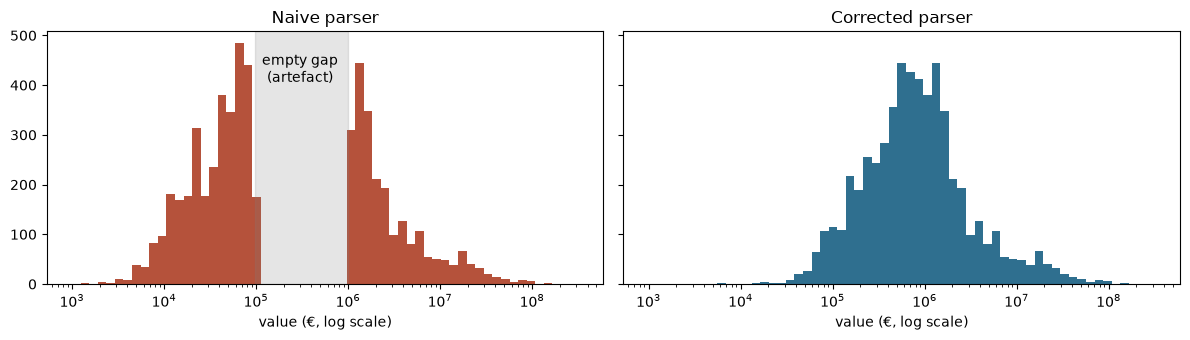

In [6]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
bins = np.logspace(3, 8.5, 60)
ax[0].hist(raw["value"].map(naive_parser), bins=bins, color="#b5523b")
ax[0].set(xscale="log", title="Naive parser", xlabel="value (€, log scale)")
ax[1].hist(raw["value"].map(parse_value), bins=bins, color="#2f6f8f")
ax[1].set(xscale="log", title="Corrected parser", xlabel="value (€, log scale)")
ax[0].axvspan(97_500, 1e6, color="grey", alpha=0.2)
ax[0].text(3e5, ax[0].get_ylim()[1] * 0.8, "empty gap\n(artefact)", ha="center")
plt.tight_layout()

## 3. Whitespace, duplicates, empty column

In [7]:
df = raw.copy()
for c in ["player", "country", "club"]:
    df[c] = df[c].astype(str).str.strip()
print("clubs before/after strip:", raw.club.nunique(), "→", df.club.nunique())

df["value"] = df["value"].map(parse_value)
df = df.drop(columns=["marking"])
dupes = df[df.duplicated(subset=["player", "club", "age", "country"], keep=False)]
display(dupes[["player", "club", "age", "value"]])
df = df.drop_duplicates(subset=["player", "club", "age", "country"]).reset_index(drop=True)
print("rows after de-duplication:", len(df))

clubs before/after strip: 689 → 683


,player,club,age,value
154,Maxime Crépeau,LAFC,29,2200000.0
156,Stefan Thesker,Holstein Kiel,32,700000.0
157,Cameron John,Rochdale,24,350000.0
158,Maxime Crépeau,LAFC,29,2200000.0
159,Stefan Thesker,Holstein Kiel,32,700000.0
160,Cameron John,Rochdale,24,350000.0
916,Sadio Mané,FC Bayern München,31,101000000.0
5229,Kylian Mbappé,Paris SG,24,153500000.0
5675,Kylian Mbappé,Paris SG,24,153500000.0
5678,Sadio Mané,FC Bayern München,31,101000000.0


rows after de-duplication: 5677


## 4. Derived columns

* `value_m`: value in € millions.
* `log_value`: natural log of euros. Values span €4k to €153.5M (a ×38,000 range) and pricing is multiplicative, so this is the modelling target.
* `is_gk`: goalkeepers have GK attributes in the 50–90 range; outfielders sit at 5–20. The split is clean:

is_gk
0    5045
1     632
Name: count, dtype: int64

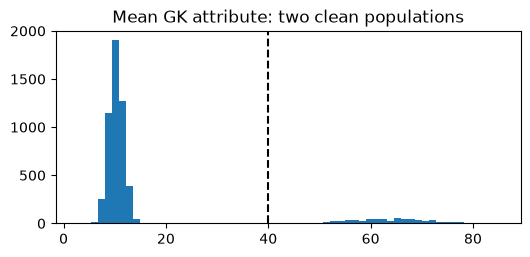

In [8]:
GK = ["gk_positioning", "gk_diving", "gk_handling", "gk_kicking", "gk_reflexes"]
gk_mean = df[GK].mean(axis=1)
plt.figure(figsize=(6, 2.5))
plt.hist(gk_mean, bins=60)
plt.axvline(40, color="k", ls="--")
plt.title("Mean GK attribute: two clean populations")
df["is_gk"] = (gk_mean > 40).astype(int)
df["value_m"] = df["value"] / 1e6
df["log_value"] = np.log(df["value"])
df.is_gk.value_counts()

In [9]:
df[["value_m", "log_value"]].describe().T

,count,mean,std,min,25%,50%,75%,max
value_m,5677.0,2.466905,7.165588,0.00400,0.350000,0.775000,1.600000,153.500000
log_value,5677.0,13.601976,1.334982,8.29405,12.765688,13.560618,14.285514,18.849211


In [10]:
OUT.parent.mkdir(exist_ok=True)
df.to_csv(OUT, index=False)
print(f"wrote {OUT} {df.shape}")

wrote ../data/player_stats_clean.csv (5677, 43)
